# 🎓 第4章 第3课：A 股被定价因子 + 简约性

**本节目标**：做两件事：

1. 用 **Fama-MacBeth** 检验哪些特征（beta/规模/价值/盈利/投资/换手/动量）被定价；
2. 用 **GRS + 平均 |α| + R²** 讨论多因子模型的简约性：因子越多越好吗？

对应原书 4.8~4.9 节。

In [1]:
import sys
from pathlib import Path

def _find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'src' / 'factor_zero').exists():
            return p
    raise FileNotFoundError('找不到仓库根目录，请从仓库内启动 notebook')
ROOT = _find_root()
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from factor_zero.data import load_ashare_panel
from factor_zero.factors import build_factor_returns
from factor_zero.models import (
    MODEL_DEFINITIONS, model_factor_frame, build_test_assets,
    evaluate_model, compare_models,
)
from factor_zero.regression import fama_macbeth, time_series_betas
from factor_zero.statistics import factor_summary

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans']
print('✅ 环境就绪，开始学习！')

✅ 环境就绪，开始学习！


In [2]:
panel = load_ashare_panel()
ret, market = panel['ret'], panel['market']
beta = ret.rolling(24).cov(market).div(market.rolling(24).var(), axis=0)
chars = {
    'BETA': beta, 'SIZE': panel['size'], 'BM': panel['bm'],
    'ROE': panel['roe'], 'INV': panel['investment'],
    'TURN': panel['turnover'], 'MOM': panel['momentum'],
}
def zscore(df):
    return df.sub(df.mean(axis=1), axis=0).div(df.std(axis=1), axis=0)
print('特征矩阵数量:', len(chars), '| 股票数:', ret.shape[1], '| 月份数:', ret.shape[0])

特征矩阵数量: 7 | 股票数: 81 | 月份数: 83


## 1) 单变量 FM：每个特征单独看

每次只放一个特征（加截距），看它的 λ 和 NW t。
这回答“单独看，这个特征被定价吗？”

In [3]:
uni = {}
for name, df in chars.items():
    X = np.nan_to_num(zscore(df).to_numpy()[:, :, None], nan=0.0)
    lam, lam_t, se, t = fama_macbeth(ret, X)
    uni[name] = {'lambda': lam[1], 'NW t': t[1]}
uni_table = pd.DataFrame(uni).T
uni_table.round(4)

,lambda,NW t
BETA,0.0000,0.0146
SIZE,0.0038,1.6599
BM,-0.0055,-2.3510
ROE,0.0026,1.4942
INV,-0.0004,-0.2741
TURN,0.0090,2.9927
MOM,0.0050,1.7356


## 2) 多变量 FM：一起看

把所有特征同时放入截面回归。
**注意**：特征之间可能相关，多变量 λ 的符号可能和单变量不同（多重共线性/相互控制）。

In [4]:
X = np.stack([np.nan_to_num(zscore(v).to_numpy(), nan=0.0)
              for v in chars.values()], axis=2)
lam, lam_t, se, t = fama_macbeth(ret, X)
multi_table = pd.DataFrame({
    'lambda': lam[1:], '标准误': se[1:], 'NW t': t[1:],
}, index=list(chars.keys()))
multi_table.round(4)

,lambda,标准误,NW t
BETA,-0.0055,0.0031,-1.7533
SIZE,0.0077,0.0016,4.8573
BM,-0.0029,0.0021,-1.3644
ROE,0.0051,0.0019,2.6665
INV,-0.0007,0.0009,-0.7881
TURN,0.0150,0.0026,5.7403
MOM,0.0023,0.0027,0.8428


### 怎么读“被定价”？

- |NW t| > 2：在 95% 置信下显著；
- λ 的符号要和经济学逻辑对照：例如价值（BM）通常预期正 λ，换手率通常预期负 λ；
- 单变量和多变量符号不一致，说明特征之间存在相关性，需要谨慎解释。

> ⚠️ 本仓库的估值/ROE/投资是教学合成面板。你在这里看到的符号和显著性
> **不能直接当作真实 A 股结论**；原书的 A 股结论请以原书样本与口径为准。

## 3) 简约性：因子越多越好吗？

把七个模型的因子数、平均 |α|、平均 R² 放在一起看。
好的模型不是“因子最多”，而是**用较少因子解释较多差异**。

In [5]:
factors = build_factor_returns(panel, n_groups=10)
assets = build_test_assets(panel, n_groups=5)
comp = compare_models(factors, assets)
comp[['k', 'mean_abs_alpha_ann', 'avg_r2', 'grs_p']].sort_values('k').round(4)

,k,mean_abs_alpha_ann,avg_r2,grs_p
model,,,,
FF3,3,0.0328,0.8291,0.8720
DHS3,3,0.0461,0.8070,0.7498
NovyMarx4,4,0.0564,0.8382,0.5979
Carhart4,4,0.0252,0.8652,0.9387
SY4,4,0.0233,0.8368,0.9728
HXZ4,4,0.0337,0.7970,0.9464
FF5,5,0.0315,0.8398,0.9435


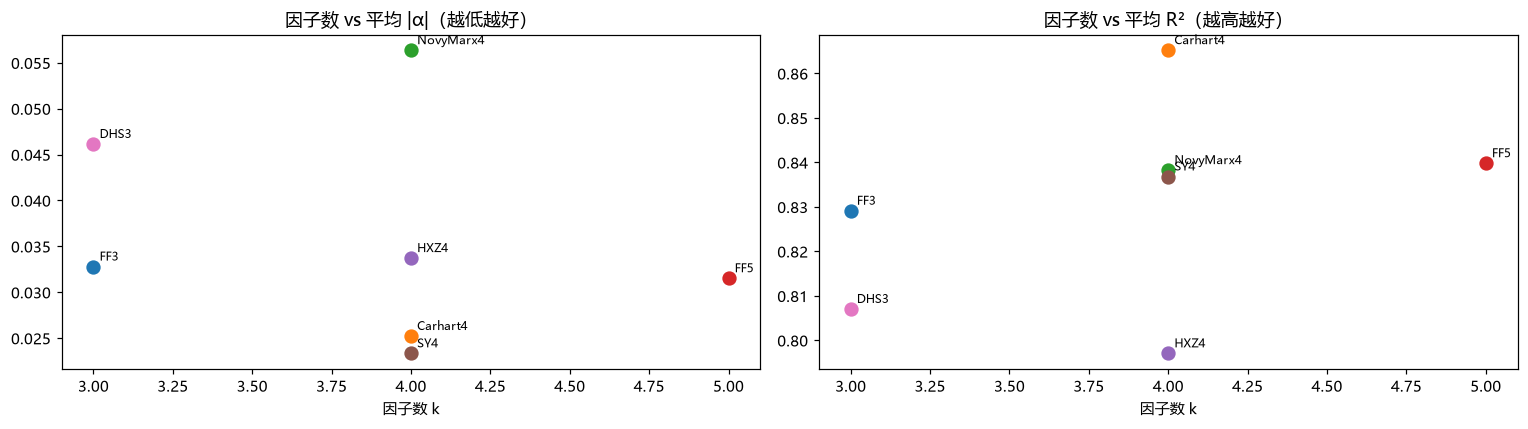

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, title in [
    (axes[0], 'mean_abs_alpha_ann', '因子数 vs 平均 |α|（越低越好）'),
    (axes[1], 'avg_r2', '因子数 vs 平均 R²（越高越好）'),
]:
    for name, row in comp.iterrows():
        ax.scatter(row['k'], row[col], s=70)
        ax.annotate(name, (row['k'], row[col]), fontsize=8,
                    xytext=(4, 4), textcoords='offset points')
    ax.set_title(title); ax.set_xlabel('因子数 k')
plt.tight_layout(); plt.show()

## ✋ 试一试

1. 把 `chars` 里的 `BETA` 去掉，多变量 FM 的符号怎么变？
2. 把 `TURN` 换成“高换手 − 低换手”，单变量 λ 的符号怎么变？
3. 在 `compare_models` 里加一个“只有 MKT”的模型，看它的平均 |α| 和 R²。

## ✅ 本节小结

- FM 可以检验哪些特征被定价；单变量和多变量要分开看；
- 特征相关时，多变量 λ 的符号可能变化；
- 模型选择要平衡解释力与简约性：因子越多，过拟合和噪声越大；
- 示例面板为教学数据，结论不能直接外推到真实 A 股。

> 下一章：异象研究——F-Score、基本面锚定反转、特质波动率。